In [ ]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:9 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Fetched 3,917 B in 1s (2,807 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependen

In [ ]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Overwriting main.cpp


In [ ]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [ ]:
%%writefile setup.sh
#!/bin/bash
echo "[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor..."
apt-get update -qq && apt-get install -y -qq libopencv-dev build-essential cmake > /dev/null

echo "[2/3] C++ uygulaması derleniyor..."
g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart

echo "[3/3] Uygulama çalıştırılıyor..."
./app

Overwriting setup.sh


In [ ]:
!bash setup.sh

[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[2/3] C++ uygulaması derleniyor...
[3/3] Uygulama çalıştırılıyor...
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [7]:

!apt-get update -qq
!apt-get install -y -qq libopencv-dev pkg-config


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Extracting templates from packages: 100%
Selecting previously unselected package libevdev2:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../000-libevdev2_1.13.1+dfsg-1build1_amd64.deb ...
Unpacking libevdev2:amd64 (1.13.1+dfsg-1build1) ...
Selecting previously unselected package at-spi2-common.
Preparing to unpack .../001-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatspi2.0-0t64:amd64.
Preparing to unpack .../002-libatspi2.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatspi2.0-0t64:amd64 (2.52.0-1build1) ...
Selecting previously unselected package libxtst6:amd64.
Preparing to unpack .../003-libxtst6_2%3a1.2.3-1.1ubuntu0.1_amd64.deb ...
Unpacking libxtst6:amd

In [8]:

%%writefile gurultu.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <random>
using namespace std;
using namespace cv;

// 1. Gauss gurultusu ekleme fonksiyonu
Mat gaussGurultusu(const Mat& resim, double sigma) {
    Mat sonuc = resim.clone();

    mt19937 rng(42);
    normal_distribution<double> dagilim(0.0, sigma);

    for (int y = 0; y < resim.rows; y++) {
        for (int x = 0; x < resim.cols; x++) {
            double deger = resim.at<uchar>(y, x);
            double gurultu = dagilim(rng);

            sonuc.at<uchar>(y, x) =
                saturate_cast<uchar>(deger + gurultu);
        }
    }

    return sonuc;
}

// 2. Salt and Pepper gurultusu ekleme fonksiyonu
Mat saltPepperGurultusu(const Mat& resim, double oran) {
    Mat sonuc = resim.clone();

    mt19937 rng(123);
    uniform_real_distribution<double> dagilim(0.0, 1.0);

    for (int y = 0; y < resim.rows; y++) {
        for (int x = 0; x < resim.cols; x++) {
            double rastgele = dagilim(rng);

            if (rastgele < oran / 2.0) {
                sonuc.at<uchar>(y, x) = 0;
            }
            else if (rastgele < oran) {
                sonuc.at<uchar>(y, x) = 255;
            }
        }
    }

    return sonuc;
}

// Harmonik matrisi hesaplama
Mat harmonikMatris(const Mat& resim) {
    Mat floatResim;
    resim.convertTo(floatResim, CV_32F);

    Mat kompleks;
    dft(floatResim, kompleks, DFT_COMPLEX_OUTPUT);

    return kompleks;
}

// Harmonik matrisini goruntuleme
Mat spektrumGoruntusu(const Mat& kompleks) {
    Mat kanallar[2];
    split(kompleks, kanallar);

    Mat genlik;
    magnitude(kanallar[0], kanallar[1], genlik);

    genlik += Scalar::all(1);
    log(genlik, genlik);

    // Dusuk frekanslari merkeze tasimak icin
    // spektrumu dort bolge halinde kaydir
    Mat kaydirilmis = Mat::zeros(
        genlik.size(), CV_32F
    );

    int satir = genlik.rows;
    int sutun = genlik.cols;

    int dy = satir / 2;
    int dx = sutun / 2;

    for (int y = 0; y < satir; y++) {
        for (int x = 0; x < sutun; x++) {
            int yeniY = (y + dy) % satir;
            int yeniX = (x + dx) % sutun;

            kaydirilmis.at<float>(yeniY, yeniX) =
                genlik.at<float>(y, x);
        }
    }

    Mat goruntu;
    normalize(kaydirilmis, goruntu,
              0, 255, NORM_MINMAX);

    goruntu.convertTo(goruntu, CV_8U);
    return goruntu;
}

int main() {
    Mat resim = imread("resim4.jpeg", IMREAD_GRAYSCALE);

    if (resim.empty()) {
        cout << "Resim bulunamadi!" << endl;
        return -1;
    }

    // Gurultu parametreleri
    double sigma = 25.0;
    double oran = 0.10;

    Mat gauss = gaussGurultusu(resim, sigma);
    Mat saltPepper = saltPepperGurultusu(resim, oran);

    // DFT harmonik matrisleri
    Mat H1 = harmonikMatris(resim);
    Mat H2 = harmonikMatris(gauss);
    Mat H3 = harmonikMatris(saltPepper);

    // Resimleri kaydet
    imwrite("orijinal.png", resim);
    imwrite("gauss.png", gauss);
    imwrite("saltpepper.png", saltPepper);

    // Harmonik matrislerinin goruntuleri
    imwrite("harmonik_orijinal.png",
            spektrumGoruntusu(H1));

    imwrite("harmonik_gauss.png",
            spektrumGoruntusu(H2));

    imwrite("harmonik_saltpepper.png",
            spektrumGoruntusu(H3));

    cout << "Tum islemler tamamlandi!" << endl;
    cout << "Gauss sigma: " << sigma << endl;
    cout << "Salt and Pepper oran: " << oran << endl;

    return 0;
}


Writing gurultu.cpp


In [9]:

!g++ -std=c++17 gurultu.cpp -o gurultu $(pkg-config --cflags --libs opencv4)
!./gurultu


Tum islemler tamamlandi!
Gauss sigma: 25
Salt and Pepper oran: 0.1


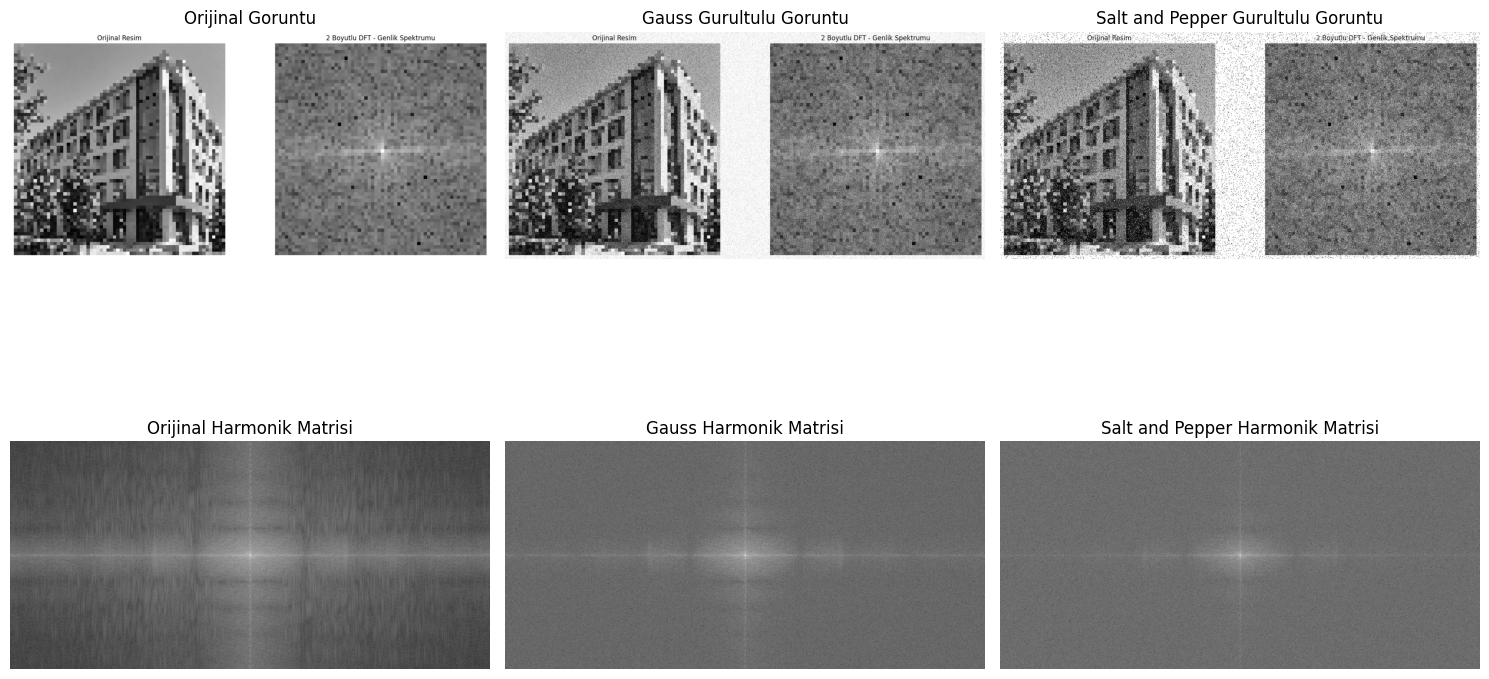

In [10]:

import cv2
import matplotlib.pyplot as plt

dosyalar = [
    "orijinal.png",
    "gauss.png",
    "saltpepper.png",
    "harmonik_orijinal.png",
    "harmonik_gauss.png",
    "harmonik_saltpepper.png"
]

basliklar = [
    "Orijinal Goruntu",
    "Gauss Gurultulu Goruntu",
    "Salt and Pepper Gurultulu Goruntu",
    "Orijinal Harmonik Matrisi",
    "Gauss Harmonik Matrisi",
    "Salt and Pepper Harmonik Matrisi"
]

fig, ax = plt.subplots(2, 3, figsize=(15, 10))

for i in range(6):
    resim = cv2.imread(dosyalar[i], 0)

    ax[i // 3, i % 3].imshow(resim, cmap="gray")
    ax[i // 3, i % 3].set_title(basliklar[i])
    ax[i // 3, i % 3].axis("off")

plt.tight_layout()
plt.savefig("gurultu_harmonik_karsilastirma.png", dpi=200)
plt.show()
